# 02 · Domain ladder

How far each Twi corpus sits from Twi as it is written on social media. FLORES-200 and MasakhaNER 2.0 are translations into Twi; AfriSenti is natively written.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90)

In [2]:
import subprocess
out = subprocess.run([sys.executable, str(ROOT/'scripts/run_ladder.py')], capture_output=True, text=True, cwd=ROOT)
print(out.stdout[-2500:])

             corpus  n_texts  n_tokens  open_vowel_token_share  digit_substitution  non_twi_letter_token_share  english_token_share  has_emoji  has_handle_or_url  word_final_open_vowel_share
FLORES-200 twi_Latn     2009   25.3051                  0.2846              0.0005                      0.0351               0.0000     0.0000                0.0                       0.1556
FLORES-200 aka_Latn     2009   25.8064                  0.2612              0.0010                      0.0314               0.0000     0.0000                0.0                       0.1655
 MasakhaNER 2.0 twi     6056   23.4171                  0.3462              0.0003                      0.0166               0.0048     0.0000                0.0                       0.2019
      AfriSenti twi     4818    9.3269                  0.0559              0.4255                      0.0464               0.0508     0.4116                0.0                       0.0384
{
  "FLORES-200 twi_Latn": {
    "tweet_token

In [3]:
pd.read_csv(ROOT/'reports/metrics/ladder_profile.csv').set_index('corpus').T.round(3)

corpus,FLORES-200 twi_Latn,FLORES-200 aka_Latn,MasakhaNER 2.0 twi,AfriSenti twi
n_texts,2009.000,2009.000,6056.000,4818.000
n_tokens,25.305,25.806,23.417,9.327
open_vowel_token_share,0.285,0.261,0.346,0.056
digit_substitution,0.000,0.001,0.000,0.426
non_twi_letter_token_share,0.035,0.031,0.017,0.046
english_token_share,0.000,0.000,0.005,0.051
has_emoji,0.000,0.000,0.000,0.412
has_handle_or_url,0.000,0.000,0.000,0.000
word_final_open_vowel_share,0.156,0.166,0.202,0.038


In [4]:
json.loads((ROOT/'reports/metrics/ladder_overlap.json').read_text())

{'FLORES-200 twi_Latn': {'tweet_token_coverage': 0.5137,
  'tweet_type_coverage': 0.1544},
 'FLORES-200 aka_Latn': {'tweet_token_coverage': 0.5351,
  'tweet_type_coverage': 0.1621},
 'MasakhaNER 2.0 twi': {'tweet_token_coverage': 0.5826,
  'tweet_type_coverage': 0.2191},
 'flores_aka_vs_twi': {'identical_lines': 8,
  'lines': 2009,
  'type_jaccard': 0.358}}

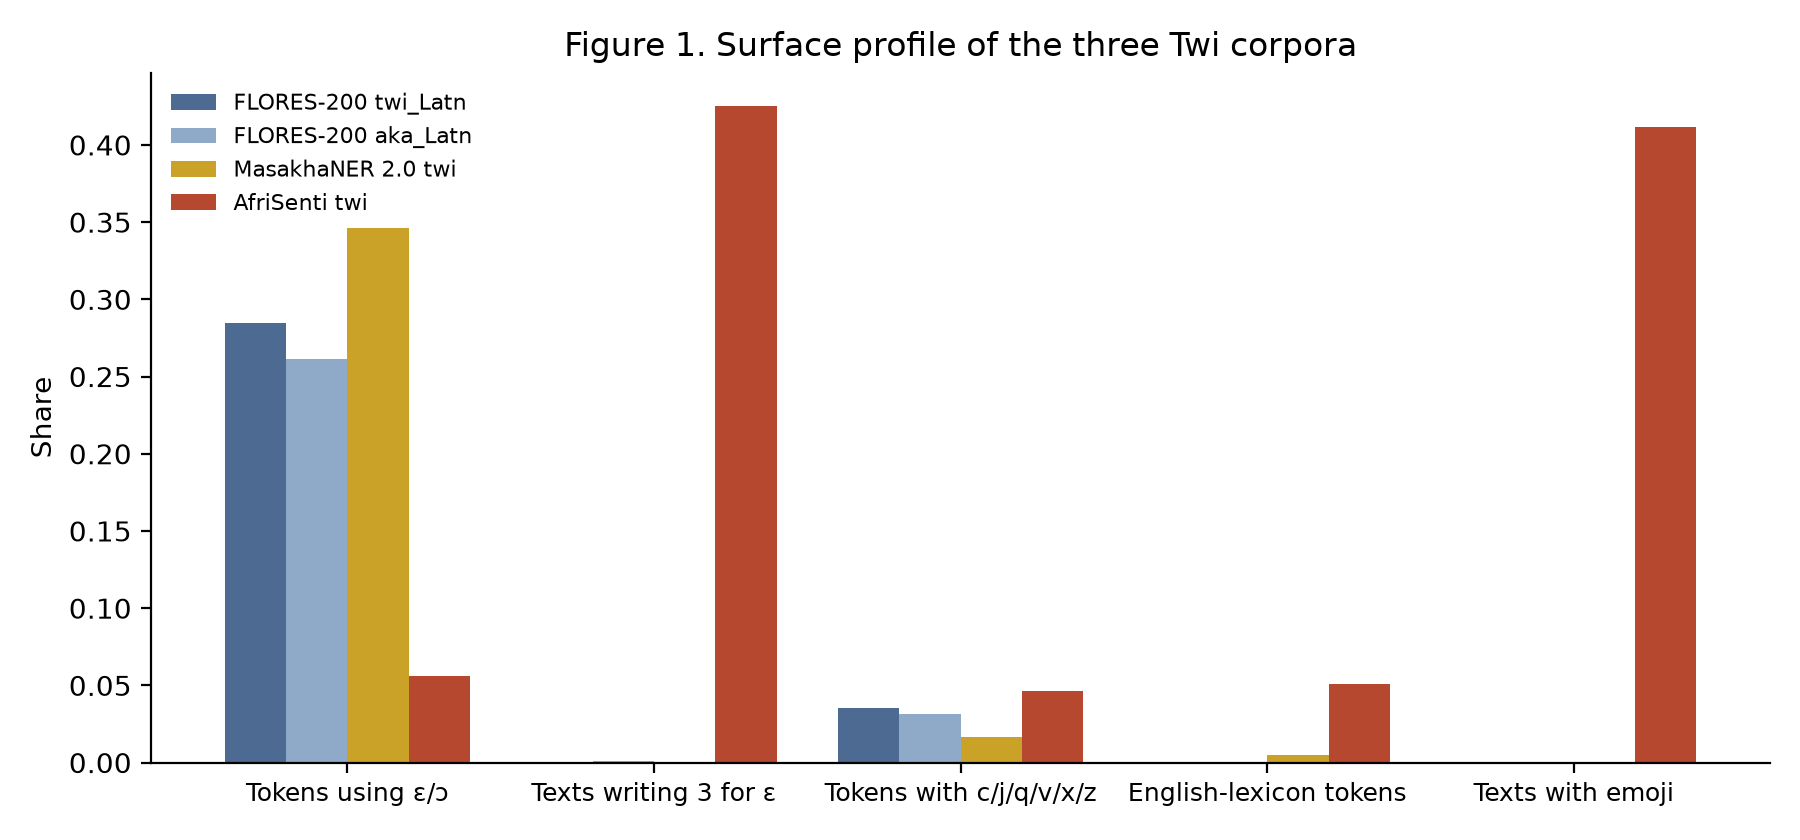

In [5]:
display(Image(str(ROOT/'reports/figures/fig1_domain_ladder.png'), width=760))

**Caveat.** English-token share is estimated with a lexicon built from FLORES English minus every word in FLORES Twi/Akan, so it is zero for FLORES by construction. Read it as a rough estimate for the other two corpora only.